## Redes Neurais Artificiais 2026.2

- **Disciplina**: Redes Neurais Artificiais 2026.2
- **Professora**: Elloá B. Guedes (ebgcosta@uea.edu.br)  
- **Github**: http://github.com/elloa  
        

Levando em conta a base de dados **_Dry Bean Dataset_**, esta segunda parte do Projeto Prático 2.2 diz respeito à proposição e avaliação de múltiplas redes neurais artificiais do tipo Feedforward Multilayer Perceptron para o problema da classificação multiclasse de variedades de feijão seco a partir de características geométricas extraídas de imagens dos grãos.

## Testando Redes Neurais com os Atributos Numéricos

1. Abra a base de dados em questão
2. Verifique que todos os atributos preditores são numéricos. O único atributo categórico é o alvo (`Class`), que não deve entrar em X
3. Armazene o atributo alvo em uma variável y e os atributos preditores em uma variável X
4. Efetue uma partição holdout 70/30 com o sklearn, distribuindo os exemplos de maneira aleatória e estratificada (`stratify=y`), com `random_state` fixo para reprodutibilidade
5. Efetue o escalonamento dos atributos

### Escalonando os atributos

O treinamento de uma rede neural artificial é mais eficiente quando os valores que lhes são fornecidos como entrada são pequenos e estão em escalas semelhantes, pois isto favorece a convergência. Isto é feito escalonando-se os atributos, mas precisa ser feito de maneira cautelosa, para que informações do conjunto de teste não sejam fornecidas no treinamento.

Há duas estratégias para tal escalonamento: normalização (que leva os valores ao intervalo [0,1]) e padronização (que centraliza os dados em média 0 e desvio padrão 1). Ambas possuem características particulares, vantagens e limitações, como é possível ver aqui: https://www.analyticsvidhya.com/blog/2020/04/feature-scaling-machine-learning-normalization-standardization/

No nosso caso, vamos usar a padronização. Assim, com os atributos preditores do treinamento, isto é, X_train, deve-se subtrair a média e dividir pelo desvio padrão. Para tanto, use o StandardScaler e ajuste-o com os dados do conjunto de treino (fit), transformando-os em seguida (transform). Depois, apenas transforme os dados do conjunto de teste (transform), usando a média e o desvio padrão calculados no treino, sem chamar o fit novamente.

Se todo o conjunto X for utilizado na padronização, a rede neural receberá informações do conjunto de teste por meio da média e do desvio padrão utilizados para preparar os dados de treinamento, o que não é desejável (vazamento de dados, ou *data leakage*).


### Continuando

1. Treine uma rede neural multilayer perceptron para este problema com uma única camada oculta de dez neurônios 
    1.1 Utilize a função de ativação ReLU  
    1.2 Utilize o solver Adam    
    1.3 Imprima o passo a passo do treinamento 
    1.4 Utilize o número máximo de épocas igual a 300
2. Com o modelo em questão, após o treinamento, apresente os resultados para o conjunto de teste:  
    2.1 Matriz de confusão  
    2.2 Acurácia  
    2.3 F-Score (F1)  
    2.4 Precisão  
    2.5 Revocação   
3. Repita o treinamento da mesma rede anterior sem imprimir o passo a passo por 10 vezes  
    3.1 Cada uma destas repetições deve ser feita com uma nova partição holdout 70/30 estratificada, e o escalonamento deve ser reajustado com os dados de treino de cada partição  
    3.2 Apresente a média e o desvio padrão da acurácia e do F-Score para o conjunto de teste  
4. Repita por 10 vezes o treinamento desta mesma rede, mas utilizando o otimizador SGD, com as mesmas 10 partições do item anterior  
    4.1 Apresente a média e o desvio padrão da acurácia e do F-Score para o conjunto de teste  
5. Houve influência da escolha do otimizador no desempenho da rede? Justifique com as médias e os desvios padrão obtidos

### Bibliotecas

In [2]:
# APENAS RODAR SE NÃO TIVER SIDO INSTALADO POR MEIO DO ENVIRONMENTS
%pip install ucimlrepo

Note: you may need to restart the kernel to use updated packages.


In [3]:
## Reservado para a importação de bibliotecas
import warnings
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from ucimlrepo import fetch_ucirepo 
from sklearn.neural_network import MLPClassifier

from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay,
                             accuracy_score, f1_score, precision_score, recall_score)
import matplotlib.pyplot as plt

### 1. Abrindo a base de dados

In [4]:
# fetch dataset 
dry_bean = fetch_ucirepo(id=602) 
  
# atributos preditores e alvos
X = dry_bean.data.features 
y = dry_bean.data.targets["Class"] 

### Partição Holdout

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.30,
    stratify=y,
    random_state=42 # 42 é a convenção mais comum (Guia do Mochileiro das Galáxias)
)

In [6]:
# Confirmar estratificação
print(y_train.value_counts(normalize=True).round(3))
print(y_test.value_counts(normalize=True).round(3))

Class
DERMASON    0.261
SIRA        0.194
SEKER       0.149
HOROZ       0.142
CALI        0.120
BARBUNYA    0.097
BOMBAY      0.038
Name: proportion, dtype: float64
Class
DERMASON    0.261
SIRA        0.194
SEKER       0.149
HOROZ       0.142
CALI        0.120
BARBUNYA    0.097
BOMBAY      0.038
Name: proportion, dtype: float64


### Escalonamento de atributos

In [7]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

R: O escalonamento é realizado após a partição dos dados. Se o `StandardScaler` fosse ajustado (`fit`) com todo o conjunto `X`, a média e o desvio padrão utilizados para padronizar os dados de treino seriam calculados incluindo os exemplos de teste. Assim, informações do conjunto de teste seriam incorporadas ao treinamento, caracterizando vazamento de dados. Como consequência, o desempenho medido no teste seria superestimado, pois o modelo não estaria sendo avaliado em dados completamente desconhecidos, como ocorreria em uma aplicação real. Por isso, o `fit` é feito apenas com `X_train`, e o conjunto de teste é somente transformado (`transform`) com os parâmetros aprendidos no treino.

### Treinamento da uma Rede Neural Multilayer Perceptron

In [8]:
mlp = MLPClassifier(
    hidden_layer_sizes=(10,),
    activation="relu",
    solver="adam",
    max_iter=300,
    verbose=True,          # imprime a perda  a cada época
    random_state=42
)
mlp.fit(X_train_scaled, y_train)

Iteration 1, loss = 2.42301022
Iteration 2, loss = 1.99189296
Iteration 3, loss = 1.71470597
Iteration 4, loss = 1.49513146
Iteration 5, loss = 1.32390321
Iteration 6, loss = 1.17278765
Iteration 7, loss = 1.01195937
Iteration 8, loss = 0.82782538
Iteration 9, loss = 0.65765618
Iteration 10, loss = 0.54924967
Iteration 11, loss = 0.48293515
Iteration 12, loss = 0.43655083
Iteration 13, loss = 0.40146620
Iteration 14, loss = 0.37431546
Iteration 15, loss = 0.35242072
Iteration 16, loss = 0.33488238
Iteration 17, loss = 0.32036679
Iteration 18, loss = 0.30815271
Iteration 19, loss = 0.29781665
Iteration 20, loss = 0.28902349
Iteration 21, loss = 0.28168829
Iteration 22, loss = 0.27489852
Iteration 23, loss = 0.26901513
Iteration 24, loss = 0.26373552
Iteration 25, loss = 0.25910210
Iteration 26, loss = 0.25520831
Iteration 27, loss = 0.25114326
Iteration 28, loss = 0.24771057
Iteration 29, loss = 0.24462889
Iteration 30, loss = 0.24172533
Iteration 31, loss = 0.23913024
Iteration 32, los

c:\Users\Arthur\anaconda3\envs\mlp-rna-2026\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (300) reached and the optimization hasn't converged yet.
  warnings.warn(


,"hidden_layer_sizes hidden_layer_sizes: array-like of shape(n_layers - 2,), default=(100,)The ith element represents the number of neurons in the ithhidden layer.","(10,)"
,"max_iter max_iter: int, default=200Maximum number of iterations. The solver iterates until convergence(determined by 'tol') or this number of iterations. For stochasticsolvers ('sgd', 'adam'), note that this determines the number of epochs(how many times each data point will be used), not the number ofgradient steps.",300
,"random_state random_state: int, RandomState instance, default=NoneDetermines random number generation for weights and biasinitialization, train-test split if early stopping is used, and batchsampling when solver='sgd' or 'adam'.Pass an int for reproducible results across multiple function calls.See :term:`Glossary <random_state>`.",42
,"verbose verbose: bool, default=FalseWhether to print progress messages to stdout.",True
,"activation activation: {'identity', 'logistic', 'tanh', 'relu'}, default='relu'Activation function for the hidden layer.- 'identity', no-op activation, useful to implement linear bottleneck, returns f(x) = x- 'logistic', the logistic sigmoid function, returns f(x) = 1 / (1 + exp(-x)).- 'tanh', the hyperbolic tan function, returns f(x) = tanh(x).- 'relu', the rectified linear unit function, returns f(x) = max(0, x)",'relu'
,"solver solver: {'lbfgs', 'sgd', 'adam'}, default='adam'The solver for weight optimization.- 'lbfgs' is an optimizer in the family of quasi-Newton methods.- 'sgd' refers to stochastic gradient descent.- 'adam' refers to a stochastic gradient-based optimizer proposed by Kingma, Diederik, and Jimmy BaFor a comparison between Adam optimizer and SGD, see:ref:`sphx_glr_auto_examples_neural_networks_plot_mlp_training_curves.py`.Note: The default solver 'adam' works pretty well on relativelylarge datasets (with thousands of training samples or more) in terms ofboth training time and validation score.For small datasets, however, 'lbfgs' can converge faster and performbetter.",'adam'
,"alpha alpha: float, default=0.0001Strength of the L2 regularization term. The L2 regularization termis divided by the sample size when added to the loss.For an example usage and visualization of varying regularization, see:ref:`sphx_glr_auto_examples_neural_networks_plot_mlp_alpha.py`.",0.0001
,"batch_size batch_size: int, default='auto'Size of minibatches for stochastic optimizers.If the solver is 'lbfgs', the classifier will not use minibatch.When set to ""auto"", `batch_size=min(200, n_samples)`.",'auto'
,"learning_rate learning_rate: {'constant', 'invscaling', 'adaptive'}, default='constant'Learning rate schedule for weight updates.- 'constant' is a constant learning rate given by 'learning_rate_init'.- 'invscaling' gradually decreases the learning rate at each time step 't' using an inverse scaling exponent of 'power_t'. effective_learning_rate = learning_rate_init / pow(t, power_t)- 'adaptive' keeps the learning rate constant to 'learning_rate_init' as long as training loss keeps decreasing. Each time two consecutive epochs fail to decrease training loss by at least tol, or fail to increase validation score by at least tol if 'early_stopping' is on, the current learning rate is divided by 5.Only used when ``solver='sgd'``.",'constant'
,"learning_rate_init learning_rate_init: float, default=0.001The initial learning rate used. It controls the step-sizein updating the weights. Only used when solver='sgd' or 'adam'.",0.001
,"power_t power_t: float, default=0.5The exponent for inverse scaling learning rate.It is used in updating effective learning rate when the learning_rateis set to 'invscaling'. Only used when solver='sgd'.",0.5


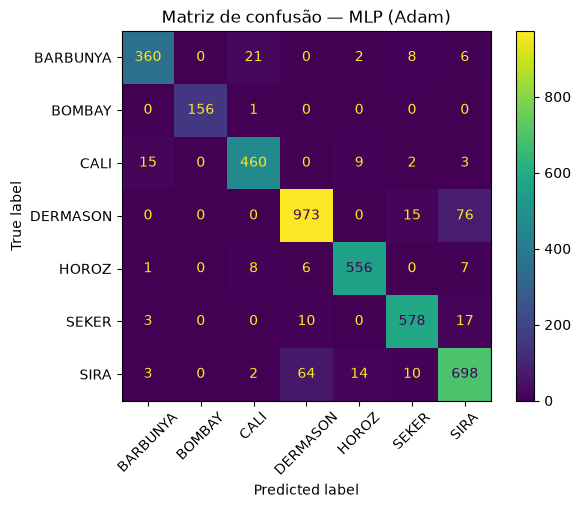

Acurácia:  0.9258
F1 macro:  0.9368
Precisão:  0.9380
Revocação: 0.9358


In [9]:
y_pred = mlp.predict(X_test_scaled)

# 2.1 matriz de confusão
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, xticks_rotation=45)
plt.title("Matriz de confusão — MLP (Adam)")
plt.show()

print(f"Acurácia:  {accuracy_score(y_test, y_pred):.4f}")
print(f"F1 macro:  {f1_score(y_test, y_pred, average='macro'):.4f}")
print(f"Precisão:  {precision_score(y_test, y_pred, average='macro'):.4f}")
print(f"Revocação: {recall_score(y_test, y_pred, average='macro'):.4f}")

In [10]:
# 3 - dez repetições Adam

seeds = list(range(10))

def aval_repeticoes(solver):
    accs, f1s = [], []
    for s in seeds:
         # 70/30
         X_tr, X_te, y_tr, y_te = train_test_split(
            X, y, test_size=0.30, stratify=y, random_state=s
        )
         scaler = StandardScaler()
         X_tr = scaler.fit_transform(X_tr)
         X_te = scaler.transform(X_te)

         modelo = MLPClassifier(
              hidden_layer_sizes=(10,), activation="relu",
              solver=solver, max_iter=300, random_state=s
         )

         modelo.fit(X_tr, y_tr)
         y_pred = modelo.predict(X_te)

         accs.append(accuracy_score(y_te, y_pred))
         f1s.append(f1_score(y_te, y_pred, average="macro"))
    return np.array(accs), np.array(f1s)


### Adam

In [11]:
acc_adam, f1_adam = aval_repeticoes("adam")
print(f"Adam -> Acurácia: {acc_adam.mean():.4f} ± {acc_adam.std():.4f} | F1: {f1_adam.mean():.4f} ± {f1_adam.std():.4f}")

c:\Users\Arthur\anaconda3\envs\mlp-rna-2026\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (300) reached and the optimization hasn't converged yet.
  warnings.warn(


Adam -> Acurácia: 0.9290 ± 0.0037 | F1: 0.9402 ± 0.0031


### SGD

In [12]:
acc_sgd, f1_sgd = aval_repeticoes("sgd")
print(f"SGD -> Acurácia: {acc_sgd.mean():.4f} ± {acc_sgd.std():.4f} | F1: {f1_sgd.mean():.4f} ± {f1_sgd.std():.4f}")

c:\Users\Arthur\anaconda3\envs\mlp-rna-2026\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (300) reached and the optimization hasn't converged yet.
  warnings.warn(
c:\Users\Arthur\anaconda3\envs\mlp-rna-2026\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (300) reached and the optimization hasn't converged yet.
  warnings.warn(


SGD -> Acurácia: 0.9247 ± 0.0044 | F1: 0.9362 ± 0.0036


### Boxplot

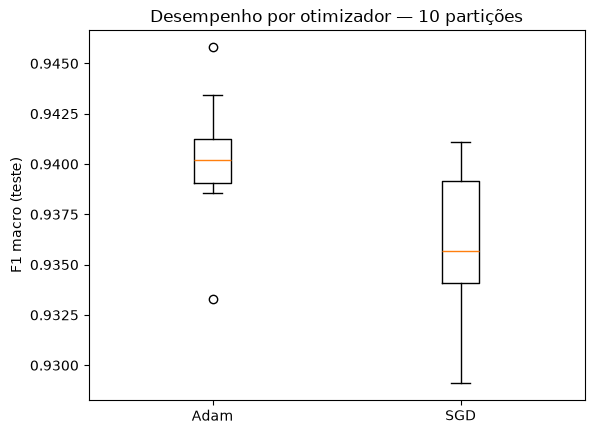

In [13]:
plt.boxplot([f1_adam, f1_sgd], tick_labels=["Adam", "SGD"])
plt.ylabel("F1 macro (teste)")
plt.title("Desempenho por otimizador — 10 partições")
plt.show()

**R:** O Adam apresentou desempenho superior nas duas métricas, com uma diferença de 0,4 em relação aos valores obtidos pelo SGD. Além disso, mostrou-se ligeiramente mais estável, apresentando menor desvio em ambas as métricas. Entretanto, como os valores das diferenças são pequenos, ambas as redes demonstram consistência entre as partições. Portanto, observa-se uma pequena influência do otimizador, com o Adam apresentando vantagem mais consistente tanto na média quanto na estabilidade.

## Discussão

Nos passos anteriores, você avaliou o desempenho de uma única arquitetura de rede neural, com uma única camada oculta de 10 neurônios e função de ativação ReLU. O otimizador utilizado, seja o SGD ou o Adam, é o algoritmo que usa o gradiente do erro (calculado pela retropropagação) para atualizar os pesos da rede. Neste sentido, a escolha do otimizador é um hiperparâmetro: ela é definida antes do treinamento, não é aprendida a partir dos dados e controla como a rede será treinada. Também são hiperparâmetros a quantidade de camadas ocultas, o número de neurônios, a função de ativação, a quantidade de épocas, a taxa de aprendizado inicial, dentre outros. Já os parâmetros da rede são os pesos e os vieses, ajustados durante o treinamento.

Cabe salientar também que você efetuou o treinamento desta rede por 10 vezes e apresentou os resultados em termos de média ± desvio padrão. Lembre-se que em uma rede neural há a inicialização aleatória de pesos e, em consequência, o desempenho está sujeito a uma flutuação estocástica. Além disso, cada repetição utilizou uma nova partição holdout, o que introduz uma segunda fonte de variação. A execução múltipla das repetições reduz a influência de uma boa ou má "sorte" na escolha dos pesos iniciais e da partição, que poderia distorcer a conclusão no caso de uma única execução, e permite estimar a variabilidade do desempenho por meio do desvio padrão.

Você também aprendeu uma estratégia para escalonar os atributos para uma melhor convergência da rede. Utilize-a em todos os treinamentos e testes propostos a seguir.

## Propondo Novas Arquiteturas

Variando a arquitetura da rede (uma ou duas camadas ocultas, com diferentes números de neurônios em cada uma delas, e a função de ativação) e os hiperparâmetros solver (Adam ou SGD) e número máximo de épocas (100, 150 e 200), atenda ao que se pede:

1. Proponha 10 arquiteturas distintas de RNAs para o problema em questão, à sua escolha
2. Avalie cada uma das arquiteturas perante todas as combinações de hiperparâmetros (2 solvers × 3 números de épocas), repetindo cada treinamento/avaliação por 10 vezes  
    2.1 Cada repetição deve utilizar uma nova partição holdout 70/30 estratificada, com o escalonamento ajustado apenas com os dados de treino, e as mesmas 10 partições devem ser usadas em todas as configurações, para que a comparação seja justa  
    2.2 Ao todo, serão 60 configurações (10 arquiteturas × 2 solvers × 3 números de épocas) e 600 treinamentos
3. Como resultado da avaliação, apresente, com base no conjunto de teste:  
    3.1 As 3 melhores configurações (arquitetura + solver + número de épocas) no tocante ao F-Score (média macro) e à acurácia, considerando a média das 10 repetições (± desvio padrão)  
    3.2 Para cada uma dessas 3 configurações, a repetição em que houve o melhor desempenho: apresente a matriz de confusão e ilustre, para cada classe, os valores de VP (verdadeiros positivos), VN (verdadeiros negativos), FP (falsos positivos) e FN (falsos negativos)

In [14]:
# RQ1 e RQ2
warnings.filterwarnings("ignore")  # avisos de não convergência (esperados)

seeds = list(range(10))
epochs = [100, 150, 200]
solvers = ["adam", "sgd"]
arquiteturas = [
     {"camadas": (10,), "ativacao": "relu"},
     {"camadas": (20, 10), "ativacao": "tanh"},
     {"camadas": (10,), "ativacao": "tanh"},
     {"camadas": (30, 20), "ativacao": "relu"},
     {"camadas": (10, 10), "ativacao": "tanh"},
     {"camadas": (5,), "ativacao": "relu"},
     {"camadas": (20,), "ativacao": "logistic"},
     {"camadas": (10, 5), "ativacao": "relu"},
     {"camadas": (30,), "ativacao": "relu"},
     {"camadas": (5, 20), "ativacao": "logistic"}
]

def model_mlp(camadas, ativacao, solver, epochs, seed):
     modelo = MLPClassifier(
                   hidden_layer_sizes=camadas, activation=ativacao,
                   solver=solver, max_iter=epochs, random_state=seed
              )
     return modelo

def aval_configuracao(X, y, camadas, ativacao, solver, epochs):
    accs, f1s, matrizes = [], [], []
    for s in seeds:
         # 70/30
         X_tr, X_te, y_tr, y_te = train_test_split(
            X, y, test_size=0.30, stratify=y, random_state=s
        )
         scaler = StandardScaler()
         X_tr = scaler.fit_transform(X_tr)
         X_te = scaler.transform(X_te)

         modelo = model_mlp(camadas, ativacao, solver, epochs, s)
         modelo.fit(X_tr, y_tr)
         y_pred = modelo.predict(X_te)

         accs.append(accuracy_score(y_te, y_pred))
         f1s.append(f1_score(y_te, y_pred, average="macro"))
         matrizes.append(confusion_matrix(y_te, y_pred))
    return np.array(accs), np.array(f1s), np.array(matrizes)

resultados = {}
for arq in arquiteturas:
    for solver in solvers:
        for e in epochs:
            chave = (arq["camadas"], arq["ativacao"], solver, e)
            resultados[chave] = aval_configuracao(
                X, y, arq["camadas"], arq["ativacao"], solver, e
            )

In [15]:
# RQ3.1
linhas = []
for (camadas, ativacao, solver, epocas), (accs, f1s, _) in resultados.items():
    linhas.append({
        "camadas": camadas, "ativacao": ativacao,
        "solver": solver, "epocas": epocas,
        "f1_media": f1s.mean(),   "f1_std": f1s.std(ddof=1),
        "acc_media": accs.mean(), "acc_std": accs.std(ddof=1),
    })

tabela = pd.DataFrame(linhas)
top3 = tabela.sort_values("f1_media", ascending=False).head(3)
print(top3.to_string(index=False))

 camadas ativacao solver  epocas  f1_media   f1_std  acc_media  acc_std
   (30,)     relu   adam     200  0.943253 0.004306   0.932321 0.004765
   (30,)     relu   adam     150  0.942409 0.004353   0.931513 0.004860
(30, 20)     relu   adam     100  0.942359 0.003604   0.931538 0.004080


In [ ]:
# RQ3.2

## Estimando o número de neurônios

Um dos problemas de pesquisa com redes neurais artificiais consiste na determinação do número de neurônios em sua arquitetura. Embora não seja possível definir a priori qual rede neural é adequada para um problema, pois isto só pode ser determinado empiricamente, mediante a avaliação de várias arquiteturas, há regras na literatura que sugerem o número de neurônios escondidos, tal como a regra da Pirâmide Geométrica, dada a seguir:

$$N_h = \alpha \cdot \sqrt{N_i \cdot N_o},$$

em que $N_h$ é o número de neurônios ocultos (a serem distribuídos em uma ou duas camadas ocultas), $N_i$ é o número de neurônios na camada de entrada e $N_o$ é o número de neurônios na camada de saída. Como $N_h$ deve ser um número inteiro, arredonde o resultado para o inteiro mais próximo.

1. Consulte a documentação da classe MLPClassifier (disponível em https://scikit-learn.org/stable/modules/generated/sklearn.neural_network.MLPClassifier.html) e obtenha os valores de $N_i$ e $N_o$ para a base _Dry Bean_, considerando o número de atributos preditores e o número de classes do problema.
2. Teste os valores de $\alpha$ como sendo iguais a $0.5$, $2$ e $3$.
3. Proponha pelo menos 30 redes neurais segundo a regra da pirâmide geométrica e teste-as nos mesmos termos estabelecidos anteriormente (solver, épocas, 10 repetições com as mesmas partições holdout, escalonamento, etc.)  
    3.1 Apresente as top-3 melhores redes no tocante à F-Score e Acurácia, com base no conjunto de teste

## Considerações Parciais

1. É possível identificar uma rede com desempenho superior às demais? 
2. Qual estratégia mostrou-se mais produtiva para a obtenção de boas arquiteturas (Estratégia Própria ou Pirâmide Geométrica)? Por quê?
3. Um número maior de épocas trouxe melhorias? Justifique com os resultados obtidos, considerando também cada um dos solvers (Adam e SGD)
4. Qual a maior dificuldade de resolução do problema proposto perante as RNAs?